<a href="https://colab.research.google.com/github/geovisiontech/DACS/blob/dev-logs/network_security.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [ ]:
from google.colab import drive

# Mount Google drive to the colab environment
drive.mount('/content/drive')

# Define the file path
security_logs_path = '/content/drive/MyDrive/DACS101/network_security (2).csv'


Mounted at /content/drive


In [ ]:
# Update the path to the correct location found by our search
security_logs_path = '/content/drive/MyDrive/network_security (2).csv'

# Load the CSV file and display the first 15 rows
df = pd.read_csv(security_logs_path)
df.head(15)

,event_id,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,packets,bytes,duration_ms,tcp_flags,action,label,attack_type,src_country
0,EVT0000001,2026-01-27 00:11:26,10.176.80.118,10.160.56.47,17447,3389,TCP,6,124400,15652,PA,ALLOW,BENIGN,NaN,US
1,EVT0000002,2026-01-27 10:13:46,10.100.38.163,10.101.41.14,55800,443,TCP,82,82766,2853,PA,ALLOW,BENIGN,NaN,US
2,EVT0000003,2026-01-25 08:08:55,10.155.248.120,10.238.67.186,28258,22,TCP,26,43822,5454,FA,ALLOW,BENIGN,NaN,GB
3,EVT0000004,2026-01-19 12:27:40,10.210.146.213,10.17.70.155,18538,443,UDP,52,37990,4039,-,ALLOW,BENIGN,NaN,US
4,EVT0000005,2026-03-11 00:45:22,10.33.170.227,10.109.252.50,55830,443,TCP,64,108529,21518,A,ALLOW,BENIGN,NaN,KE
5,EVT0000006,2026-02-03 14:31:12,10.244.137.2,10.106.80.177,53997,8080,TCP,23,134089,19440,S,ALLOW,BENIGN,NaN,US
6,EVT0000007,2026-02-17 21:47:41,10.218.29.20,10.49.179.161,58207,3389,UDP,68,5828,3911,-,ALLOW,BENIGN,NaN,ZA
7,EVT0000008,2026-03-20 11:49:17,10.94.236.44,10.128.34.229,26207,22,TCP,86,47685,27974,"S,A",ALLOW,BENIGN,NaN,US
8,EVT0000009,2026-02-11 23:25:12,10.201.92.70,10.169.137.214,64974,8080,TCP,94,138639,19359,PA,ALLOW,BENIGN,NaN,SG
9,EVT0000010,2026-02-22 15:14:42,10.22.94.198,10.115.208.134,19576,53,TCP,96,7604,23007,"S,A",ALLOW,BENIGN,NaN,ZA


In [ ]:
df.info()
df.describe()
# df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 15 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   event_id     object
 1   timestamp    object
 2   src_ip       object
 3   dst_ip       object
 4   src_port     int64 
 5   dst_port     int64 
 6   protocol     object
 7   packets      int64 
 8   bytes        int64 
 9   duration_ms  int64 
 10  tcp_flags    object
 11  action       object
 12  label        object
 13  attack_type  object
 14  src_country  object
dtypes: int64(5), object(10)
memory usage: 228.9+ MB


,src_port,dst_port,packets,bytes,duration_ms
count,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06,2.000000e+06
mean,3.328301e+04,1.979698e+03,1.100047e+02,2.086190e+05,1.501060e+04
std,1.862276e+04,6.181247e+03,4.033505e+02,1.261946e+06,1.099483e+04
min,1.024000e+03,2.000000e+00,1.000000e+00,4.000000e+01,1.000000e+00
25%,1.715600e+04,8.000000e+01,2.700000e+01,3.213600e+04,6.539000e+03
50%,3.325900e+04,4.430000e+02,5.900000e+01,7.279500e+04,1.438600e+04
75%,4.943900e+04,4.450000e+02,9.200000e+01,1.139350e+05,2.239300e+04
max,6.553500e+04,6.553500e+04,5.000000e+03,1.999771e+07,1.200000e+05


In [ ]:
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values)

Missing values per column:
 event_id             0
timestamp            0
src_ip               0
dst_ip               0
src_port             0
dst_port             0
protocol             0
packets              0
bytes                0
duration_ms          0
tcp_flags            0
action               0
label                0
attack_type    1820041
src_country          0
dtype: int64


In [ ]:
# The 'success' column does not exist in this dataset.
# Using 'action' instead to see the distribution of allowed vs blocked traffic.
df['action'].value_counts()

,count
action,
ALLOW,1820041
BLOCK,140342
ALERT,39617


In [ ]:
# Count blocked connections per source IP
# Filter the DataFrame to include only where the action status is 'BLOCK'
failed_events = df[df['action'] == 'BLOCK']

# Group blocked events by source IP ('src_ip') and count occurrences
failed_events_per_ip = failed_events.groupby('src_ip')['action'].count().sort_values(ascending=False)

# Display the top 10 IP addresses with the most blocked network connections
failed_events_per_ip.head(10)

,action
src_ip,
192.0.2.192,170
198.51.100.204,168
192.0.2.132,168
192.0.2.11,166
192.0.2.174,164
192.0.2.170,164
203.0.113.189,163
192.0.2.149,162
203.0.113.78,161


In [ ]:
# The top IP is the strongest indicator of a threat
top_ips = failed_events_per_ip.index[:2]
print("The top IPs are:", top_ips)

The top IPs are: Index(['192.0.2.192', '198.51.100.204'], dtype='object', name='src_ip')


In [ ]:
# Count blocked connections per destination IP (most targeted systems)
# Group by 'dst_ip' and count how many times each destination was targeted
targeted_destinations = failed_events.groupby('dst_ip')['action'].count().sort_values(ascending=False)

# Display the top 10 targeted destination IPs
targeted_destinations.head(10)

,action
dst_ip,
10.171.42.167,3
10.44.169.221,3
10.242.129.126,3
10.173.105.89,3
10.136.186.28,2
10.58.116.154,2
10.71.57.39,2
10.4.170.147,2
10.82.85.152,2


In [ ]:
# The variable 'targeted_user' does not exist because there is no user column in the dataset.
# We will use the correct variable 'targeted_destinations' to find the top targeted destination IP.
top_targeted_ip = targeted_destinations.index[0]
print("The top targeted destination IP is:", top_targeted_ip)

The top targeted destination IP is: 10.171.42.167


In [9]:
# Since 'critical_success' and 'user' do not exist in the dataset, we will find successful allowed connections from our top suspected IPs
critical_success = df[(df['src_ip'].isin(top_ips)) & (df['action'] == 'ALLOW')]

# Display the connection logs of these potentially compromised or targeting IPs
print(critical_success[['src_ip', 'dst_ip', 'timestamp', 'action']].head())

# List unique source IPs that successfully connected
compromised_ips = critical_success['src_ip'].unique()
print("\nThe source IPs with successful connections are:", ', '.join(compromised_ips))

Empty DataFrame
Columns: [src_ip, dst_ip, timestamp, action]
Index: []

The source IPs with successful connections are: 


In [8]:
# Quick recovery cell: Reload data and restore all active variables
import pandas as pd
from google.colab import drive

# 1. Ensure Google Drive is mounted
try:
    drive.mount('/content/drive')
except Exception as e:
    print(f"Drive mount message: {e}")

# 2. Reload the dataframe
security_logs_path = '/content/drive/MyDrive/network_security (2).csv'
try:
    df = pd.read_csv(security_logs_path)
    print("Dataset loaded successfully!")
except Exception as e:
    print(f"\nCould not load dataset automatically: {e}")
    print("Please ensure you approved the Google Drive mount permission popup.")

# 3. Re-establish variables for analysis
if 'df' in globals():
    failed_events = df[df['action'] == 'BLOCK']
    failed_events_per_ip = failed_events.groupby('src_ip')['action'].count().sort_values(ascending=False)
    top_ips = failed_events_per_ip.index[:2]
    targeted_destinations = failed_events.groupby('dst_ip')['action'].count().sort_values(ascending=False)
    print("Session state restored! You can now run your analysis cells.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Session state restored! You can now run your analysis cells.


In [12]:
# Recalculate critical success using current session variables
critical_success = df[(df['src_ip'].isin(top_ips)) & (df['action'] == 'ALLOW')]

# Display the connection logs if any exist
print(critical_success[['src_ip', 'dst_ip', 'timestamp', 'action']])

# Confirm the successfully connected source IPs
compromised_ips = critical_success['src_ip'].unique()
print("The source IPs with successful connections are:", ', '.join(compromised_ips))

Empty DataFrame
Columns: [src_ip, dst_ip, timestamp, action]
Index: []
The source IPs with successful connections are: 


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use the correct column name 'action' instead of 'success'
action_count = df['action'].value_counts()

plt.figure(figsize=(6, 4))
# Assigning x to hue and setting legend=False to prevent the deprecation warning
sns.barplot(
    x=action_count.index,
    y=action_count.values,
    hue=action_count.index,
    legend=False,
    palette=['lightgreen', 'salmon', 'skyblue']
)
plt.title('Overall Connection Action Distribution')
plt.xlabel('Action Status')
plt.ylabel('Total Count')
plt.show()

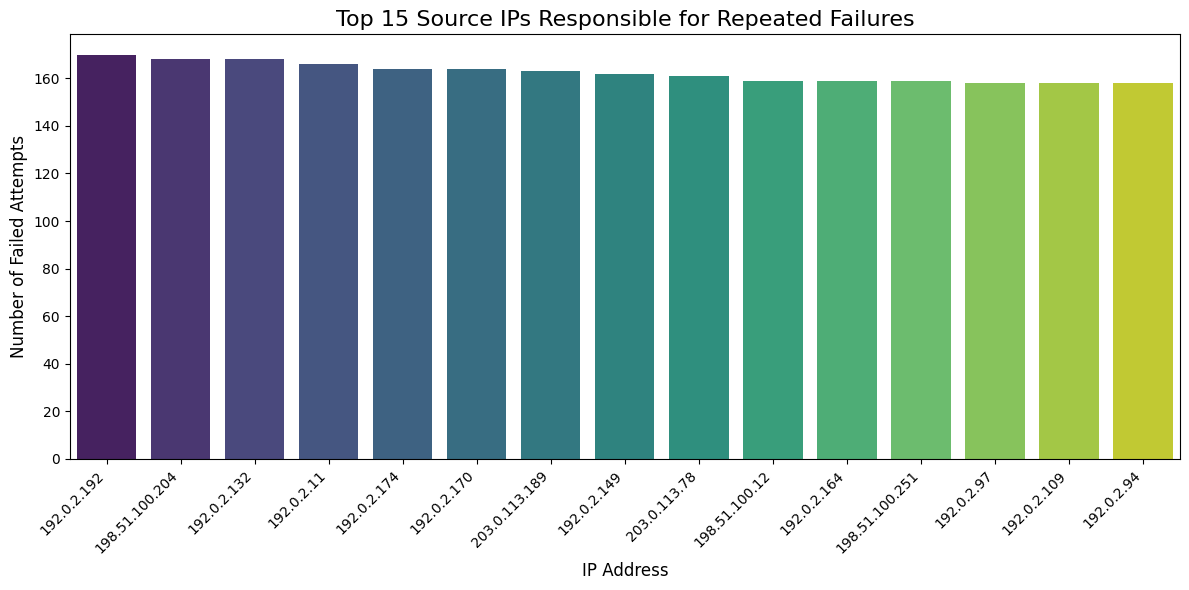

In [18]:
# Only plot the top 15 IPs to prevent rendering issues
top_failed_ips = failed_events_per_ip.head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_failed_ips.index,
    y=top_failed_ips.values,
    hue=top_failed_ips.index,
    legend=False,
    palette='viridis'
)
plt.title('Top 15 Source IPs Responsible for Repeated Failures', fontsize=16)
plt.xlabel('IP Address', fontsize=12)
plt.ylabel('Number of Failed Attempts', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

In [21]:
# Show the breakdown of flagged security events in our dataset
flagged_attacks = df[df['attack_type'].notna()]
print(f"Total flagged attack events: {len(flagged_attacks)}")
print("\nBreakdown of detected attack types:")
print(flagged_attacks['attack_type'].value_counts())

# Display the actions taken on these attacks
print("\nActions taken on these attacks:")
print(flagged_attacks['action'].value_counts())

flagged_attacks.head()

Total flagged attack events: 179959

Breakdown of detected attack types:
attack_type
Port Scan            50071
Brute Force          49998
DDoS                 39936
Data Exfiltration    23856
Malware C2           16098
Name: count, dtype: int64

Actions taken on these attacks:
action
BLOCK    140342
ALERT     39617
Name: count, dtype: int64


,event_id,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,packets,bytes,duration_ms,tcp_flags,action,label,attack_type,src_country
38,EVT0000039,2026-02-11 23:55:23,10.98.96.8,10.43.71.17,16301,21,TCP,17,3767,7573,A,BLOCK,MALICIOUS,Brute Force,KE
60,EVT0000061,2026-03-09 13:16:42,192.0.2.132,10.76.39.192,52927,11121,TCP,5,727,46,S,BLOCK,MALICIOUS,Port Scan,SG
72,EVT0000073,2026-01-02 10:40:21,10.17.201.38,10.224.108.33,9445,8443,TCP,67,29228,32348,-,BLOCK,MALICIOUS,Malware C2,NL
92,EVT0000093,2026-03-22 12:49:12,192.0.2.92,10.18.118.228,33980,443,UDP,367,4238448,105621,-,BLOCK,MALICIOUS,Data Exfiltration,KE
97,EVT0000098,2026-02-20 18:00:40,10.233.242.110,10.34.125.47,52523,3389,TCP,11,4804,1887,A,BLOCK,MALICIOUS,Brute Force,KE


In [22]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df.head()
# print(df[['timestamp', 'hour', 'action']].head(20))

,event_id,timestamp,src_ip,dst_ip,src_port,dst_port,protocol,packets,bytes,duration_ms,tcp_flags,action,label,attack_type,src_country,hour
0,EVT0000001,2026-01-27 00:11:26,10.176.80.118,10.160.56.47,17447,3389,TCP,6,124400,15652,PA,ALLOW,BENIGN,NaN,US,0
1,EVT0000002,2026-01-27 10:13:46,10.100.38.163,10.101.41.14,55800,443,TCP,82,82766,2853,PA,ALLOW,BENIGN,NaN,US,10
2,EVT0000003,2026-01-25 08:08:55,10.155.248.120,10.238.67.186,28258,22,TCP,26,43822,5454,FA,ALLOW,BENIGN,NaN,GB,8
3,EVT0000004,2026-01-19 12:27:40,10.210.146.213,10.17.70.155,18538,443,UDP,52,37990,4039,-,ALLOW,BENIGN,NaN,US,12
4,EVT0000005,2026-03-11 00:45:22,10.33.170.227,10.109.252.50,55830,443,TCP,64,108529,21518,A,ALLOW,BENIGN,NaN,KE,0


In [27]:
# 1. Identify off-hour events (before 8 AM or after 5 PM) that were successfully 'ALLOW'ed
suspicious_hours = df[((df['hour'] < 8) | (df['hour'] > 17)) & (df['action'] == 'ALLOW')]
print(f"Total successful off-hour connections: {len(suspicious_hours)}")
print(suspicious_hours[['timestamp', 'src_ip', 'dst_ip', 'action']].head())

# 2. Filter for actual security-related incidents (attack_type) happening off-hours
suspicious_actions = df[((df['hour'] < 8) | (df['hour'] > 17)) & (df['attack_type'].notna())]
print(f"\nOff-hour flagged attack actions: {len(suspicious_actions)}")
print(suspicious_actions['attack_type'].value_counts())

# 3. Overall distribution of traffic by hour of the day
action_counts = df['hour'].value_counts().sort_index()
print("\nTotal events hourly distribution:")
print(action_counts.head(24))

Total successful off-hour connections: 1060684
             timestamp         src_ip          dst_ip action
0  2026-01-27 00:11:26  10.176.80.118    10.160.56.47  ALLOW
4  2026-03-11 00:45:22  10.33.170.227   10.109.252.50  ALLOW
6  2026-02-17 21:47:41   10.218.29.20   10.49.179.161  ALLOW
8  2026-02-11 23:25:12   10.201.92.70  10.169.137.214  ALLOW
10 2026-02-20 22:30:29  10.35.198.216   10.157.130.64  ALLOW

Off-hour flagged attack actions: 105218
attack_type
Brute Force          29145
Port Scan            29113
DDoS                 23466
Data Exfiltration    13998
Malware C2            9496
Name: count, dtype: int64

Total events hourly distribution:
hour
0     83149
1     83110
2     83340
3     83822
4     83267
5     82811
6     83056
7     83316
8     83625
9     83495
10    83776
11    83152
12    83399
13    83223
14    82983
15    83787
16    83201
17    83457
18    83504
19    83284
20    83602
21    83205
22    83168
23    83268
Name: count, dtype: int64


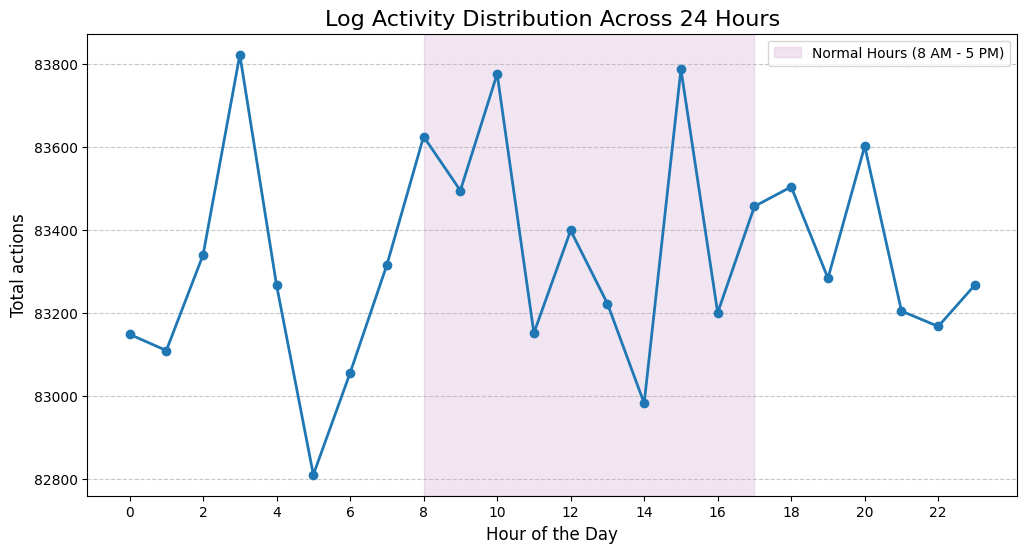

In [26]:
plt.figure(figsize=(12, 6))

# Create a line plot to show the distribution across 24 hours
plt.plot(action_counts.index, action_counts.values,
         marker='o',          # Show specific data points
         linestyle='-',       # Connect the points
         color='#1f77b4',     # Use a distinct color (e.g., standard blue)
         linewidth=2)         # Make the line slightly thicker

# Set clear title and labels
plt.title('Log Activity Distribution Across 24 Hours', fontsize=16)
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Total actions', fontsize=12)

# Set the X-axis ticks to show all 24 hours (0 through 23)
plt.xticks(range(0, 24, 2))

# Add a grid for easier reading of values
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight a possible "normal" working window for contrast
plt.axvspan(8, 17, color='purple', alpha=0.1, label='Normal Hours (8 AM - 5 PM)')
plt.legend()

plt.show()